In [1]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [2]:
#1. import database / data

In [92]:
# create connection
conn = sqlite3.connect('customer_churn.db')

In [93]:
# select table names
sql_query = """
         select name 
         from sqlite_master
         where type = 'table'
"""
table = pd.read_sql(sql_query,conn)

# create dataframe

for table_name in table['name']:
     df = pd.read_sql(f"select * from {table_name}", conn)
     globals()[f"df_{table_name}"] = df
     print(f"Created dataframe: df_{table_name}")

conn.close()
   


Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


In [94]:
# df_db_customer.head()
df_db_customer.tail()


,customerid,name,country,state,gender,dob,interests,pincode
16,0020-JDNXP,rikim,India,Meghalaya,Female,1994-08-19 00:00:00,None,None
17,0021-IKXGC,vishakha,India,Rajasthan,Female,2000-09-02 00:00:00,None,None
18,0022-TCJCI,raghvendra,India,Telangana,Male,1983-12-30 00:00:00,None,None
19,0023-HGHWL,rishabh,India,Uttar Pradesh,Men,1991-05-14 00:00:00,None,None
20,0023-UYUPN,sudevi,India,Maharashtra,Women,1977-10-06 00:00:00,None,None


In [95]:
df_db_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     object
 1   name        21 non-null     object
 2   country     18 non-null     object
 3   state       21 non-null     object
 4   gender      21 non-null     object
 5   dob         21 non-null     object
 6   interests   4 non-null      object
 7   pincode     0 non-null      object
dtypes: object(8)
memory usage: 1.4+ KB


In [96]:
# After seeing info we know 
# a. rename column - name
# b. drop column interest and pincode 
# c. change datatype - dob
# d. data standardization - gender
# e. fix missing values - country 

In [97]:
# a. rename column - name
df_db_customer.rename( columns = {'name':'customer_name'}, inplace = True)

In [98]:
df_db_customer.head()

,customerid,customer_name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,None,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,None,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [99]:
# b. drop column interest and pincode 
# df_db_customer.drop(df_db_customer.columns[6:])
#df_db_customer.drop(df_db_customer.columns[-2:],axis = 1)

df_db_customer.drop(columns = ['interests','pincode'],axis = 1,inplace = True)

In [100]:
df_db_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerid     21 non-null     object
 1   customer_name  21 non-null     object
 2   country        18 non-null     object
 3   state          21 non-null     object
 4   gender         21 non-null     object
 5   dob            21 non-null     object
dtypes: object(6)
memory usage: 1.1+ KB


In [101]:
# c. change datatype - dob
# use builtin function

df_db_customer['dob']=pd.to_datetime(df_db_customer['dob'])

In [102]:
# d. data standardization - gender

df_db_customer['gender'] = df_db_customer['gender'].replace({'Men': 'Male', 'Women' : 'Female'})

In [103]:
df_db_customer['gender']

0       Male
1       Male
2     Female
3       Male
4     Female
5     Female
6     Female
7       Male
8     Female
9       Male
10      Male
11    Female
12    Female
13    Female
14      Male
15    Female
16    Female
17    Female
18      Male
19      Male
20    Female
Name: gender, dtype: object

In [104]:
# e. fix missing values - country 

In [105]:
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,None,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,None,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,None,Telangana,Female,2004-12-01


In [106]:
state_country_mapping = df_db_customer.dropna(subset = ['country']).set_index('state')['country'].to_dict()
state_country_mapping
df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))



In [107]:
df_db_customer[['state','country']]

,state,country
0,Maharashtra,India
1,Karnataka,India
2,Delhi,India
3,Nagaland,India
4,Delhi,India
5,Delhi,India
6,Meghalaya,India
7,Rajasthan,India
8,Kathmandu,Nepal
9,Kathmandu,Nepal


In [108]:
df_db_customer.head()

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05


In [109]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,None,None,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,None,None,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,None,None,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [110]:
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     object 
 1   subscription_start_date  21 non-null     object 
 2   subscription_type        21 non-null     object 
 3   renewal_date             21 non-null     object 
 4   plan_type                21 non-null     object 
 5   contract_type            21 non-null     object 
 6   cancellation_date        6 non-null      object 
 7   cancellation_reason      6 non-null      object 
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 1.9+ KB


In [111]:
# change datatype of the date

In [112]:
# Easy Way
# date_colms = ['subscription_start_date', 'renewal_date','cancellation_date' ]
# df_db_subscription[date_colms] = df_db_subscription[date_colms].apply(pd.to_datetime)

df_db_subscription['subscription_start_date'] = pd.to_datetime(df_db_subscription['subscription_start_date'])
df_db_subscription['renewal_date'] = pd.to_datetime(df_db_subscription['renewal_date'])
df_db_subscription['cancellation_date'] = pd.to_datetime(df_db_subscription['cancellation_date'])

In [113]:
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     object        
 1   subscription_start_date  21 non-null     datetime64[ns]
 2   subscription_type        21 non-null     object        
 3   renewal_date             21 non-null     datetime64[ns]
 4   plan_type                21 non-null     object        
 5   contract_type            21 non-null     object        
 6   cancellation_date        6 non-null      datetime64[ns]
 7   cancellation_reason      6 non-null      object        
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[ns](3), float64(1), int64(2), object(5)
memory usage: 1.9+ KB


In [114]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,None
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,None


In [115]:
df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      object
 1   complaint_date  9 non-null      object
 2   escalations     9 non-null      object
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      object
dtypes: int64(1), object(5)
memory usage: 560.0+ bytes


In [116]:
df_db_support.drop(columns = ['col_1', 'comment'], inplace = True)

In [117]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28 00:00:00,N,60
1,0003-MKNFE,2024-08-28 00:00:00,Y,10
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20
3,0013-MHZWF,2025-03-18 00:00:00,N,90
4,0013-SMEOE,2024-11-01 00:00:00,N,30


In [118]:
df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])

In [119]:
df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      object        
 1   complaint_date  9 non-null      datetime64[ns]
 2   escalations     9 non-null      object        
 3   csat_score      9 non-null      int64         
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 416.0+ bytes


In [120]:
# 3. Feature Engineering and Data Analysis

In [121]:
# create a new column using existing column - churn_flag
df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(),1,0)

In [122]:
 df_db_subscription.head(3)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,34,0


In [123]:
# fix df_db_support table duplicates then merge
df =  (df_db_subscription
            .merge(df_db_customer, on = 'customerid', how = 'left')
            .merge(df_db_support,on = 'customerid', how = 'left') )

df

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,12,0,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,N,60.0
2,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0
3,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,34,0,lalita,India,Delhi,Female,1978-02-15,NaT,NaN,NaN
4,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,8,0,mohan,India,Nagaland,Male,2001-08-30,NaT,NaN,NaN
5,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1,mira,India,Delhi,Female,1990-05-05,2024-01-20,Y,20.0
6,0013-MHZWF,2022-06-18,Paid,2025-06-18,Standard,Annual,NaT,None,17.99,720,22,0,durga,India,Delhi,Female,1988-12-10,2025-03-18,N,90.0
7,0013-SMEOE,2021-09-30,Refferal,2024-09-30,Basic,Monthly,2024-11-15,Not enough content,8.99,230,79,1,mina,India,Meghalaya,Female,1976-09-21,2024-11-01,N,30.0
8,0014-BMAQU,2020-02-14,Organic,2025-02-14,Premium,Annual,NaT,None,22.99,1840,5,0,madan,India,Rajasthan,Male,1999-03-14,NaT,NaN,NaN
9,0015-UOCOJ,2023-07-22,Organic,2024-07-22,Standard,Monthly,NaT,None,13.99,240,34,0,maya,Nepal,Kathmandu,Female,1985-07-07,NaT,NaN,NaN


In [124]:
df.shape

(23, 20)

In [125]:
# where are the rows are duplicates

In [126]:
df_db_subscription['customerid'].nunique()

21

In [127]:
df_db_customer['customerid'].nunique()

21

In [128]:
df_db_support['customerid'].nunique()

7

In [129]:
df_db_support['customerid'].size

9

In [130]:
# The duplicate records are present in the data set beacause of df_db_support table
df[df.duplicated(['customerid'])]

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score
2,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0
20,0022-TCJCI,2023-09-14,Refferal,2024-09-14,Basic,Monthly,2024-09-14,Forgot to cancel trial,16.99,42,99,1,raghvendra,India,Telangana,Male,1983-12-30,2024-09-14,N,90.0


In [131]:
df_db_support

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30
5,0017-IUDMW,2024-04-10,Y,25
6,0019-EFAEP,2024-09-27,Y,30
7,0022-TCJCI,2024-09-13,Y,10
8,0022-TCJCI,2024-09-14,N,90


In [132]:
# we delete the first and keep last 
df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform('count')
df_db_support
# we delete the first and keep last 
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid',keep = 'last')

df_db_support

,customerid,complaint_date,escalations,csat_score,complaint_count
2,0013-EXCHZ,2024-01-20,Y,20,1
5,0017-IUDMW,2024-04-10,Y,25,1
1,0003-MKNFE,2024-08-28,Y,10,2
8,0022-TCJCI,2024-09-14,N,90,2
6,0019-EFAEP,2024-09-27,Y,30,1
4,0013-SMEOE,2024-11-01,N,30,1
3,0013-MHZWF,2025-03-18,N,90,1


In [133]:
# merge
df =  (df_db_subscription
            .merge(df_db_customer, on = 'customerid', how = 'left')
            .merge(df_db_support,on = 'customerid', how = 'left') )

df

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,...,0,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0,2.0
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,...,0,lalita,India,Delhi,Female,1978-02-15,NaT,NaN,NaN,NaN
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,...,0,mohan,India,Nagaland,Male,2001-08-30,NaT,NaN,NaN,NaN
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,1,mira,India,Delhi,Female,1990-05-05,2024-01-20,Y,20.0,1.0
5,0013-MHZWF,2022-06-18,Paid,2025-06-18,Standard,Annual,NaT,None,17.99,720,...,0,durga,India,Delhi,Female,1988-12-10,2025-03-18,N,90.0,1.0
6,0013-SMEOE,2021-09-30,Refferal,2024-09-30,Basic,Monthly,2024-11-15,Not enough content,8.99,230,...,1,mina,India,Meghalaya,Female,1976-09-21,2024-11-01,N,30.0,1.0
7,0014-BMAQU,2020-02-14,Organic,2025-02-14,Premium,Annual,NaT,None,22.99,1840,...,0,madan,India,Rajasthan,Male,1999-03-14,NaT,NaN,NaN,NaN
8,0015-UOCOJ,2023-07-22,Organic,2024-07-22,Standard,Monthly,NaT,None,13.99,240,...,0,maya,Nepal,Kathmandu,Female,1985-07-07,NaT,NaN,NaN,NaN
9,0016-QLJIS,2022-04-03,Organic,2025-04-03,Basic,Annual,NaT,None,6.99,335,...,0,arjun,Nepal,Kathmandu,Male,1993-10-29,NaT,NaN,NaN,NaN


In [134]:
df.to_csv('exported_churn_data.csv', index = False)

In [135]:
# Data Analysis 

In [136]:
# 1. Churn Rate : % of people churn

In [137]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='object')

In [138]:
churn_rate = round(df['churn_flag'].mean() * 100,2)
print('Churn Rate = ',churn_rate,"%")

Churn Rate =  28.57 %


In [139]:
# 2. Retention Rate -> opposite of Churn Rate

In [140]:
retention_rate = 100 - churn_rate
print('Retention Rate = ',retention_rate,'%')

Retention Rate =  71.43 %


In [141]:
# 3. Churn by Plan type
churn_by_plan_type = round(df.groupby('plan_type')['churn_flag'].mean() * 100,2).reset_index(name = 'churn_rate_pct')

In [142]:
churn_by_plan_type

# higher churn % in basic plan_type 

,plan_type,churn_rate_pct
0,Basic,60.00
1,Premium,14.29
2,Standard,22.22


In [143]:
# 4. Churn by state + sum(revenue) & count of users

df[df["churn_flag"] == 1].groupby("state").agg({
    "monthly_charges": "sum",
    "customerid": "count"
})

,monthly_charges,customerid
state,,
Delhi,13.99,1
Karnataka,20.98,2
Meghalaya,21.98,2
Telangana,16.99,1


In [144]:
# churn by subscription type  sum(revenue) & count of users

df[df['churn_flag']==1].groupby('subscription_type').agg({'monthly_charges': 'sum'})

,monthly_charges
subscription_type,
Paid,12.99
Refferal,60.95


In [145]:
# 5. ARPU Average revenue per unit
arpu = round(df['monthly_charges'].mean(),2)
print('Average Revenue Per Unit',arpu,'%')

Average Revenue Per Unit 18.85 %


In [146]:
# homework - calculate customer age
today = pd.Timestamp.today() # current date
df['new_age'] = ((today - df['dob']).dt.days/365).astype('int')
df['new_age'] 

0     44
1     30
2     48
3     25
4     36
5     37
6     50
7     27
8     41
9     32
10    29
11    45
12    21
13    34
14    46
15    40
16    32
17    26
18    42
19    35
20    49
Name: new_age, dtype: int64

In [147]:
# 6. AVG customer tenure
# count of days user has used our services : cancellation_date else current date

today = pd.Timestamp.today()

df['tenure_days'] = np.where(

    df['cancellation_date'].notna(),
    (df['cancellation_date'] - df['subscription_start_date']).dt.days,
    (today - df['subscription_start_date']).dt.days
)

df['tenure_days'] = df['tenure_days'].astype('int')

avg_tenure = df['tenure_days'].mean()

print('Average Tenure = ', round(avg_tenure),0)

Average Tenure =  1563 0


In [148]:
# 7. Revenue Risk - Revenue lost from churned users

revenue_at_risk = df.loc[df['churn_flag'] == 1,'monthly_charges'].sum()
print("Revenue at Risk (Rs 'K') = ", revenue_at_risk)

Revenue at Risk (Rs 'K') =  73.94


In [149]:
# 8. Esclation Rate -> Means problem not solve

esclation_rate = (df['escalations'] == 'Y').mean() * 100
print("Esclation Rate = ",round(esclation_rate,2),'%')

Esclation Rate =  19.05 %


In [150]:
# 9. Avg Complaint Rate Per User
avg_complaint_rate = df['complaint_count'].sum() / df['customerid'].nunique()
print('Avg Complaint Rate = ',round(avg_complaint_rate *100,2),'%' )

Avg Complaint Rate =  42.86 %


In [248]:
# Change escalation into 0,1 for better correlation
#df['escalations'] = np.where(df['escalations']== 'Y',1,0) # encoding str into int

# 10. Correlation -> Escalations vs Churn
corr_df = df[['escalations','churn_flag']].dropna()


corr_df['escalations'].corr(df['churn_flag'])






np.float64(nan)

In [157]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'new_age', 'tenure_days'],
      dtype='object')

In [166]:
# Create column - Churn risk to categorzed churn score
conditions = [
    (df['churn_score'] < 50),
    (df['churn_score'] >= 50) & (df['churn_score'] < 70),
    (df['churn_score'] > 70)
]

choices = ['Low','Medium','High']

df['churn_risk'] = np.select(conditions,choices,default = 'unknown')

In [168]:
df[['churn_score','churn_risk']]

,churn_score,churn_risk
0,12,Low
1,91,High
2,34,Low
3,8,Low
4,88,High
5,22,Low
6,79,High
7,5,Low
8,34,Low
9,41,Low


In [ ]:
# 4. Data Visualization

In [170]:
df_visual = df.copy()

In [172]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'new_age', 'tenure_days', 'churn_risk'],
      dtype='object')

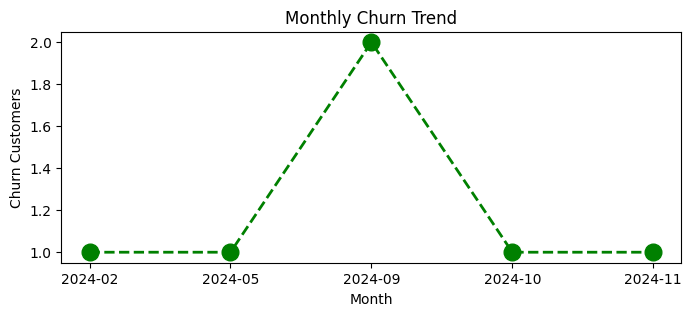

In [190]:
# 4.1 Monthly Churn Trend (Time Series KPI)
df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')

churn_trend = df_visual[df_visual['churn_flag'] == 1].groupby('cancellation_month').size()
plt.figure(figsize = (8,3))
plt.plot(churn_trend.index.astype(str),churn_trend.values,color='green', marker='o', linestyle='dashed',
     linewidth=2, markersize=12)
plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churn Customers')
plt.show()

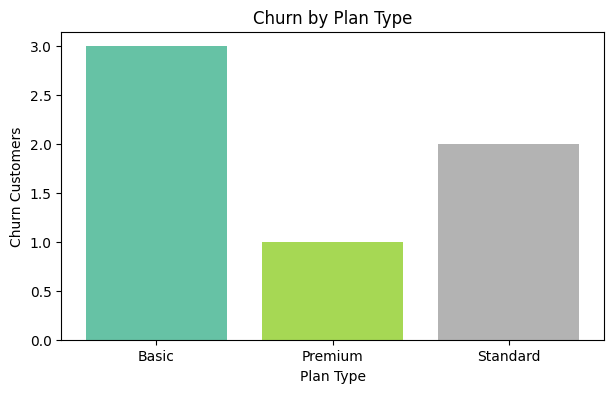

In [202]:
# 4.2 Churn by plan type

bar_v = df_visual[df_visual['churn_flag']==1].groupby('plan_type').size()

plt.figure(figsize = (7,4))
colors = plt.cm.Set2(np.linspace(0,1,len(bar_v)))

plt.bar(bar_v.index,bar_v.values, color = colors )

plt.title('Churn by Plan Type')
plt.xlabel('Plan Type')
plt.ylabel('Churn Customers')
plt.show()

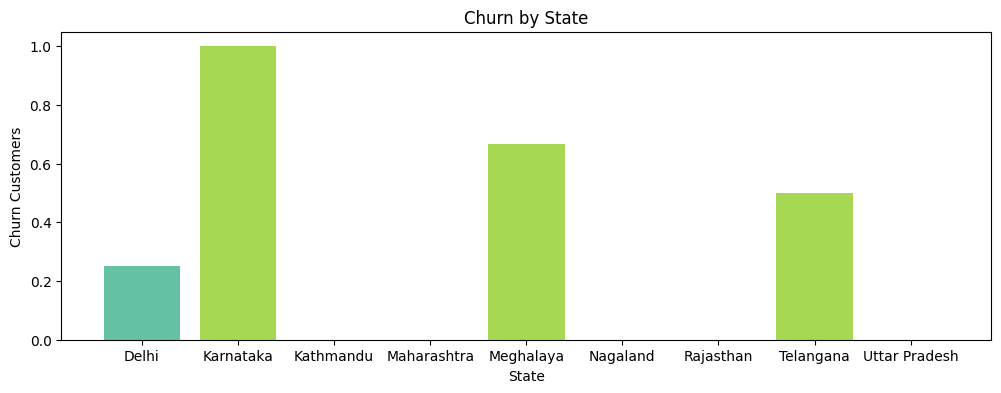

In [212]:
# 4.3 Churn by state

churn_state = df_visual.groupby('state')['churn_flag'].mean()

colors = plt.cm.Set2(np.linspace(0,1,len(bar_v)))

plt.figure(figsize = (12,4))

plt.bar(churn_state.index,churn_state.values, color = colors)
plt.title('Churn by State')
plt.xlabel('State')
plt.ylabel('Churn Customers')
plt.show()


In [214]:
# Visualization using seaborn

In [217]:
# Heatmap (correlation matrix)

df_visual[['plan_type','contract_type','churn_score','churn_flag','churn_risk','escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,Low,0
1,Premium,Annual,91,1,High,0
2,Basic,Monthly,34,0,Low,0
3,Premium,Annual,8,0,Low,0
4,Standard,Monthly,88,1,High,0


In [234]:
df_encoded = df_visual[['plan_type','contract_type','churn_score','churn_flag','churn_risk','escalations']].head()
categorial_cols = ['plan_type','contract_type','churn_risk']


for col in categorial_cols :
    df_encoded[col] = df_encoded[col].astype('category').cat.codes


In [237]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,2,0,12,0,1,0
1,1,0,91,1,0,0
2,0,1,34,0,1,0
3,1,0,8,0,1,0
4,2,1,88,1,0,0


<Axes: >

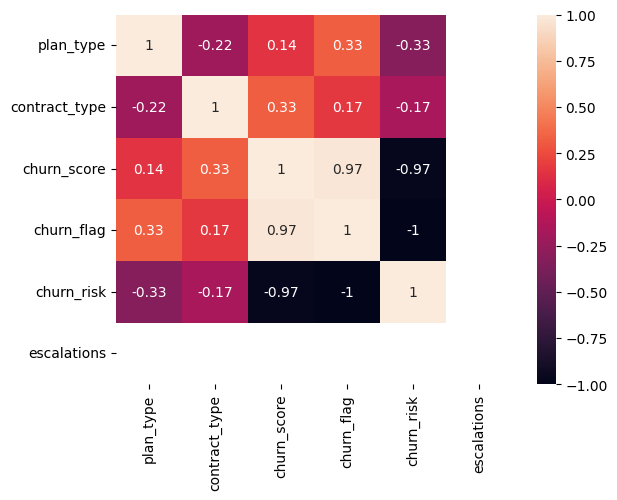

In [236]:
sns.heatmap(df_encoded.corr(), annot = True)

In [242]:
import warnings
warnings.filterwarnings('ignore')


In [243]:
# Correct method of encoding - based on priority

df_encoded = df_visual[['plan_type','contract_type','churn_score','churn_flag','churn_risk','escalations']]

order_mapping = {
    'plan_type' : ['Basic','Standard','Premium'],
    'contract_type' : ['Monthly','Annual'],
    'churn_risk' : ['Low','Medium','High']
}


for col,order in order_mapping.items() :
    df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'),categories = order, ordered = True).codes

In [249]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,1,1,12,0,0,0
1,2,1,91,1,2,0
2,0,0,34,0,0,0
3,2,1,8,0,0,0
4,1,0,88,1,2,0


<Axes: >

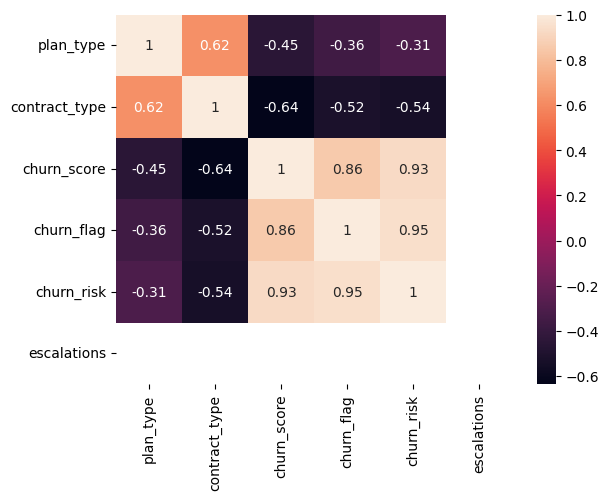

In [250]:
sns.heatmap(df_encoded.corr(), annot = True)

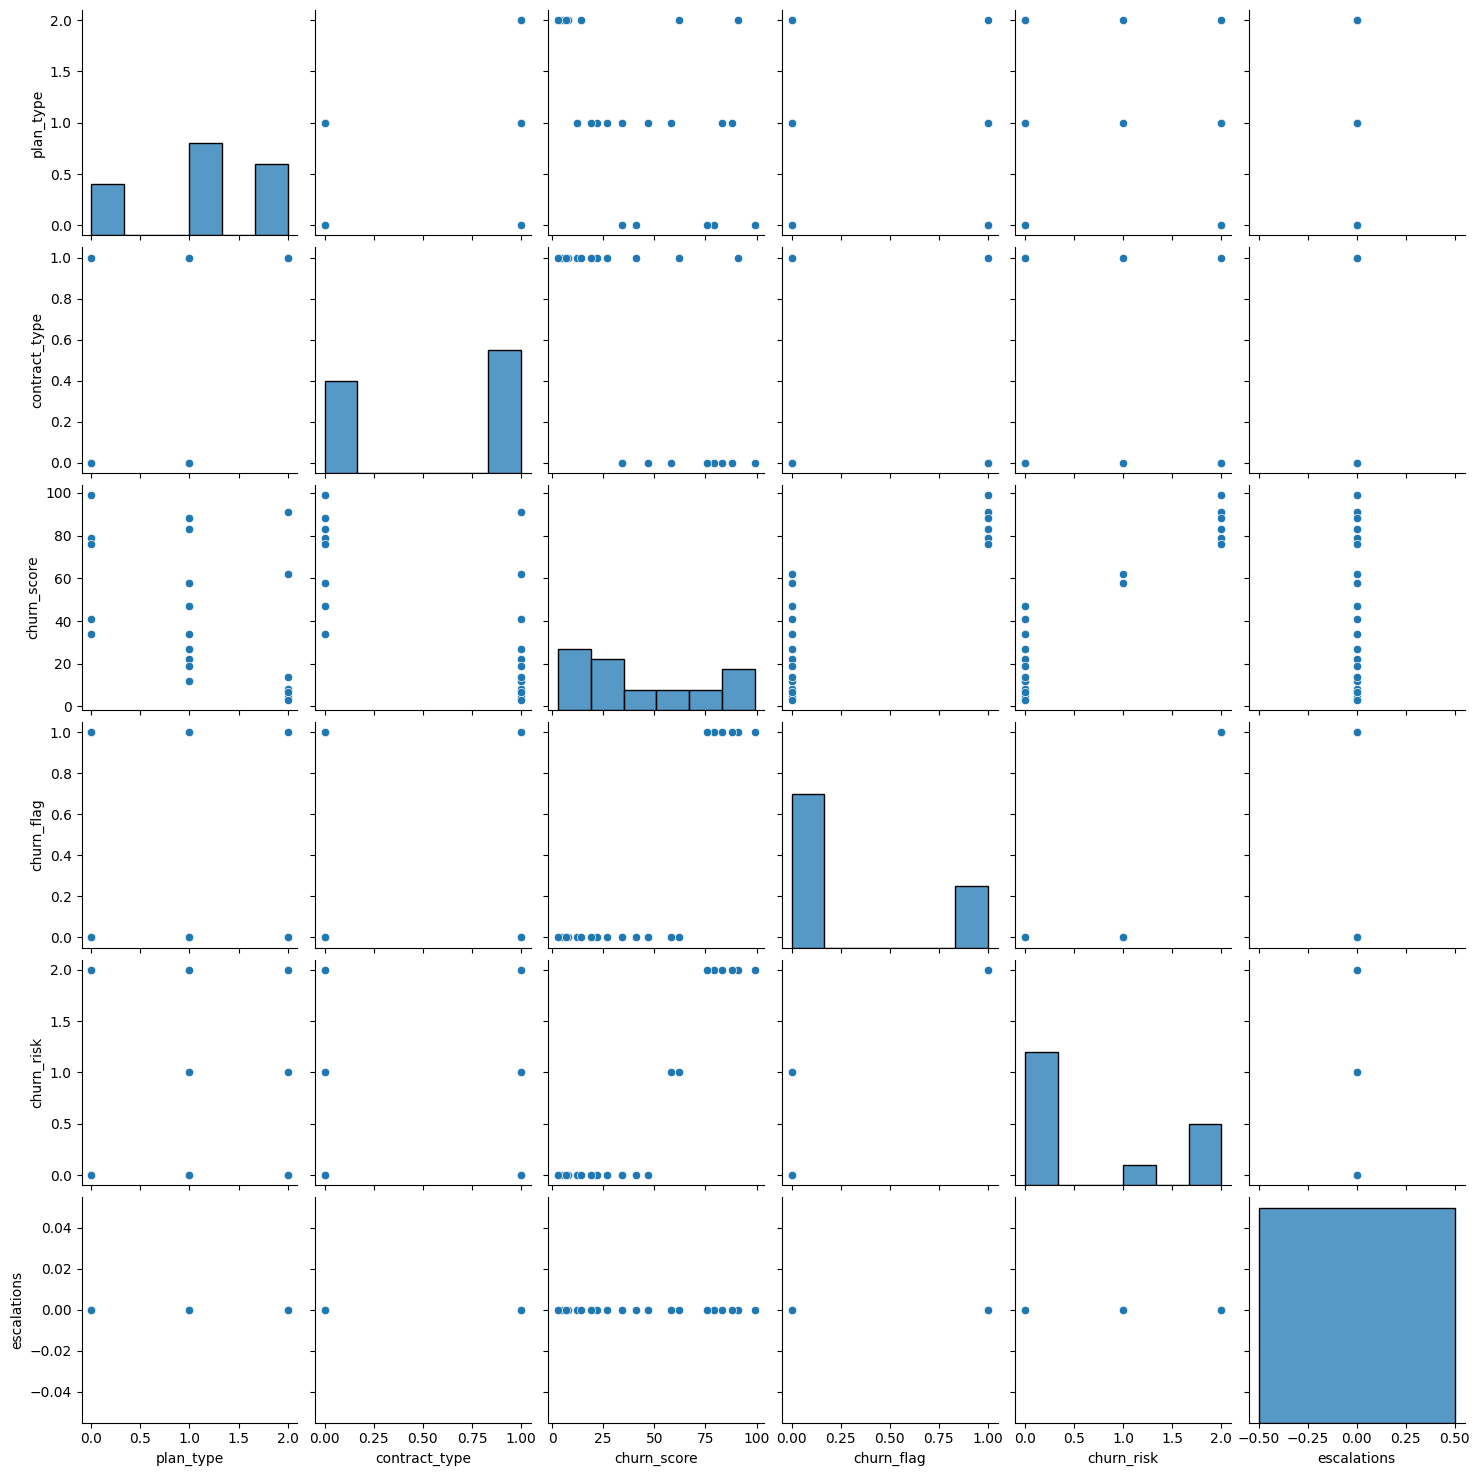

In [251]:
# pairplot
sns.pairplot(df_encoded)

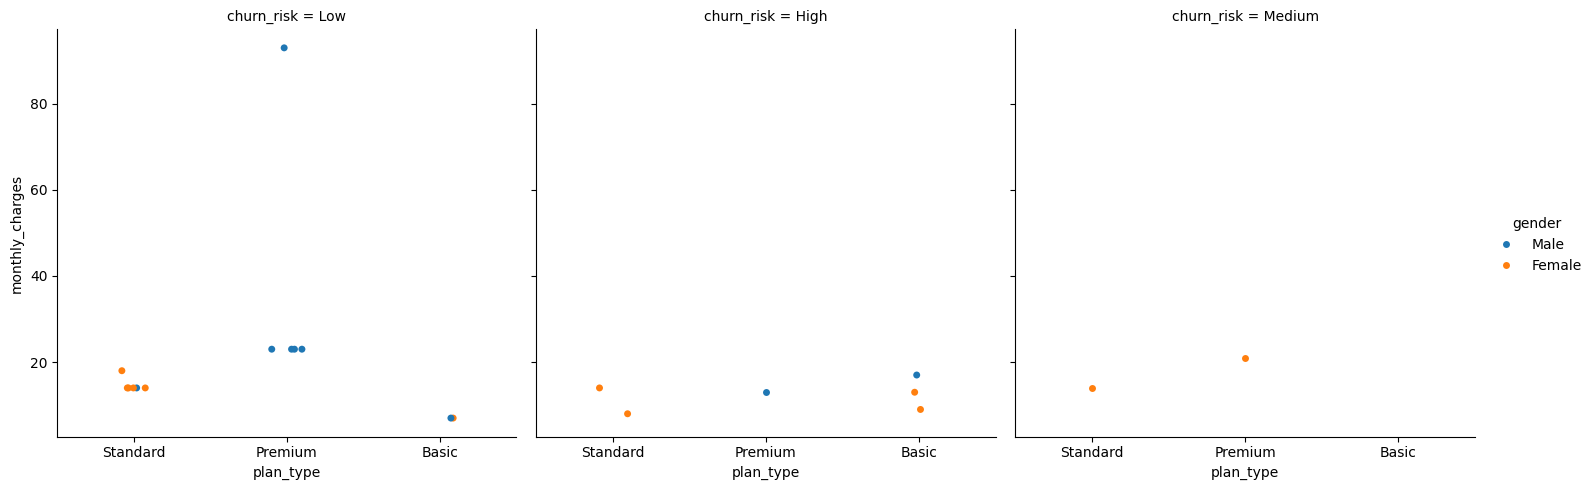

In [253]:
# catplt/facegrid plot -> multi-dim comparision
sns.catplot(data= df_visual,
    x='plan_type',
    y='monthly_charges',
    hue='gender',
    col='churn_risk', )

In [254]:
# 5 Pivot Table

In [256]:
pd.pivot_table(
    df_visual,
    values = 'churn_flag',
    index = 'plan_type',
    aggfunc = 'mean'
    
).reset_index()

,plan_type,churn_flag
0,Basic,0.600000
1,Premium,0.142857
2,Standard,0.222222


In [258]:
pd.pivot_table (

    df_visual,
    index='plan_type',
    values= ['monthly_charges','customerid', 'churn_flag'],
    aggfunc = {
    'monthly_charges' : 'sum',
    'customerid' : 'nunique',
    'churn_flag' : 'mean'
    }


)

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91
